In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import  precision_recall_curve, average_precision_score
from sklearn.ensemble import RandomForestClassifier
import joblib
import os

In [3]:
df = pd.read_csv("D:/mannu/ML/churn_predictor/data/processed/cleaned_data.csv")
df = df.drop(columns=["tenure_bucket"])

In [4]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,PaymentMethod_Electronic check,PaymentMethod_Mailed check,MultipleLines_Yes,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,early_tenure
0,1,0,1,0,1,0,1,29.85,29.85,0,...,1,0,0,0,1,0,0,0,0,1
1,0,0,0,0,34,1,0,56.95,1889.50,0,...,0,1,0,1,0,1,0,0,0,0
2,0,0,0,0,2,1,1,53.85,108.15,1,...,0,1,0,1,1,0,0,0,0,1
3,0,0,0,0,45,0,0,42.30,1840.75,0,...,0,0,0,1,0,1,1,0,0,0
4,1,0,0,0,2,1,1,70.70,151.65,1,...,1,0,0,0,0,0,0,0,0,1


In [5]:
X = df.drop("Churn", axis=1)

In [6]:
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService_Fiber optic,...,PaymentMethod_Electronic check,PaymentMethod_Mailed check,MultipleLines_Yes,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,early_tenure
0,1,0,1,0,1,0,1,29.85,29.85,0,...,1,0,0,0,1,0,0,0,0,1
1,0,0,0,0,34,1,0,56.95,1889.50,0,...,0,1,0,1,0,1,0,0,0,0
2,0,0,0,0,2,1,1,53.85,108.15,0,...,0,1,0,1,1,0,0,0,0,1
3,0,0,0,0,45,0,0,42.30,1840.75,0,...,0,0,0,1,0,1,1,0,0,0
4,1,0,0,0,2,1,1,70.70,151.65,1,...,1,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,0,1,1,24,1,1,84.80,1990.50,0,...,0,1,1,1,0,1,1,1,1,0
7039,1,0,1,1,72,1,1,103.20,7362.90,1,...,0,0,1,0,1,1,0,1,1,0
7040,1,0,1,1,11,0,1,29.60,346.45,0,...,1,0,0,1,0,0,0,0,0,1
7041,0,1,1,0,4,1,1,74.40,306.60,1,...,0,1,1,0,0,0,0,0,0,1


In [7]:
X.isnull().sum()

gender                                    0
SeniorCitizen                             0
Partner                                   0
Dependents                                0
tenure                                    0
PhoneService                              0
PaperlessBilling                          0
MonthlyCharges                            0
TotalCharges                             11
InternetService_Fiber optic               0
InternetService_No                        0
Contract_One year                         0
Contract_Two year                         0
PaymentMethod_Credit card (automatic)     0
PaymentMethod_Electronic check            0
PaymentMethod_Mailed check                0
MultipleLines_Yes                         0
OnlineSecurity_Yes                        0
OnlineBackup_Yes                          0
DeviceProtection_Yes                      0
TechSupport_Yes                           0
StreamingTV_Yes                           0
StreamingMovies_Yes             

In [8]:
y = df["Churn"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42)

In [10]:
pipe=Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # Handing missing Data
    ("scaler", StandardScaler()),                   # Feature Scaling data
    ("model", LogisticRegression(max_iter=1000))    #Model
])

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. I

Make predictions 

In [11]:
y_pred = pipe.predict(X_test)

y_prob = pipe.predict_proba(X_test)[:,1]

In [12]:
roc_auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("ROC_AUC:", round(roc_auc,4))
print("\n Confusion matrix:", cm)
print("\n Classification report:", report)


ROC_AUC: 0.8607

 Confusion matrix: [[935 101]
 [161 212]]

 Classification report:               precision    recall  f1-score   support

           0       0.85      0.90      0.88      1036
           1       0.68      0.57      0.62       373

    accuracy                           0.81      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.81      0.81      1409



ROC = Receiver Operating Characteristic curve
 
 """How well does my model separate churners from non-churners across all thresholds?"""


Axes (memorize this)

X-axis: False Positive Rate (FPR)
→ % of non-churners you wrongly flag(Yani model ne galti se kitne loyal customers ko "churn" bol diya.)

Y-axis: True Positive Rate (TPR) = Recall
→ % of churners you correctly catch(Yani model ne sahi mein kitne "churn" hone waale logon ko pakad liya.)


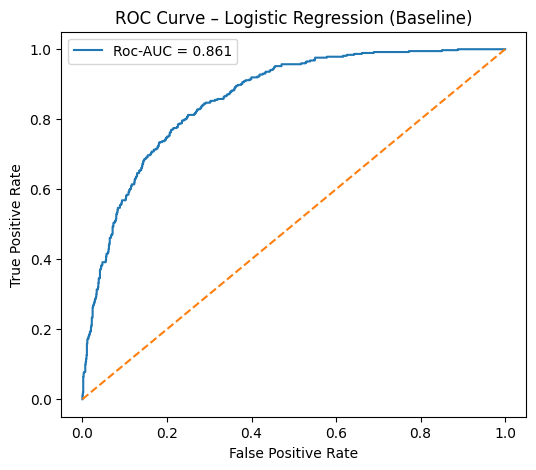

In [13]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"Roc-AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Logistic Regression (Baseline)")
plt.legend()
plt.show()

In [14]:
custom_threshold = 0.35
y_pred_custom = (y_prob >= custom_threshold).astype(int)

print(confusion_matrix(y_test, y_pred_custom))
print(classification_report(y_test, y_pred_custom))


[[835 201]
 [ 98 275]]
              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1036
           1       0.58      0.74      0.65       373

    accuracy                           0.79      1409
   macro avg       0.74      0.77      0.75      1409
weighted avg       0.81      0.79      0.80      1409



Ectract coefficient from your trained pipeline

In [15]:
featur_names = X_train.columns
cofficients = pipe.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "feature": featur_names,
    "coefficient": cofficients
}).sort_values(by="coefficient", ascending=False)

coef_df.head(10)

,feature,coefficient
9,InternetService_Fiber optic,0.602928
8,TotalCharges,0.370686
23,early_tenure,0.262930
22,StreamingMovies_Yes,0.224290
16,MultipleLines_Yes,0.179935
21,StreamingTV_Yes,0.176931
6,PaperlessBilling,0.161542
14,PaymentMethod_Electronic check,0.144832
1,SeniorCitizen,0.062748
2,Partner,0.031060


covert coefficients -> odds Ratios(important)

In [16]:
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])
coef_df.sort_values(by="odds_ratio", ascending=False).head(10)

,feature,coefficient,odds_ratio
9,InternetService_Fiber optic,0.602928,1.827462
8,TotalCharges,0.370686,1.448727
23,early_tenure,0.262930,1.300735
22,StreamingMovies_Yes,0.224290,1.251433
16,MultipleLines_Yes,0.179935,1.197139
21,StreamingTV_Yes,0.176931,1.193549
6,PaperlessBilling,0.161542,1.175322
14,PaymentMethod_Electronic check,0.144832,1.155845
1,SeniorCitizen,0.062748,1.064758
2,Partner,0.031060,1.031548


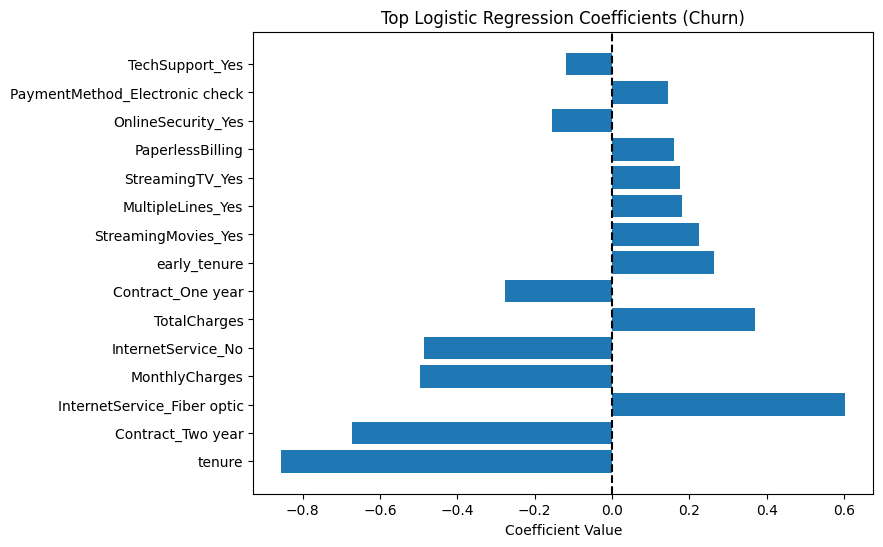

In [17]:
top_featues = coef_df.sort_values(
    by="coefficient",
    key=abs,
    ascending=False
).head(15)

plt.figure(figsize=(8,6))
plt.barh(top_featues["feature"], top_featues["coefficient"])
plt.axvline(0, color="black", linestyle="--")
plt.title("Top Logistic Regression Coefficients (Churn)")
plt.xlabel("Coefficient Value")
plt.show()


## Precison-Recall curve

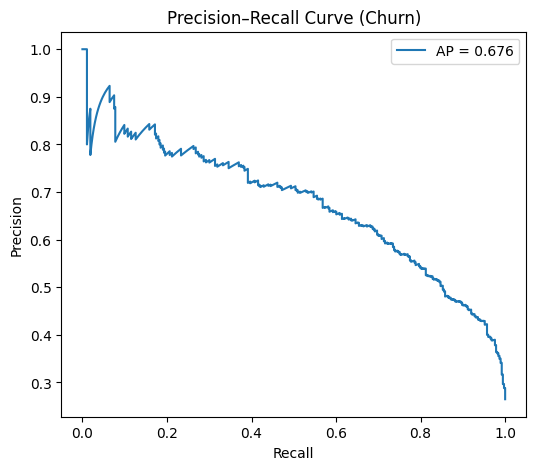

In [18]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

avg_precision = average_precision_score(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"AP = {avg_precision:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve (Churn)")
plt.legend()
plt.show()


## connecting PR curve to my threshold

In [19]:
threshold_idx = np.argmin(np.abs(thresholds- 0.35))

precision[threshold_idx], recall[threshold_idx]

(np.float64(0.5786163522012578), np.float64(0.739946380697051))

## Random Forest

In [20]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth = 8,
    min_samples_leaf = 50,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [21]:
y_prob_rf = rf.predict_proba(X_test)[:,1]
y_pred_rf = (y_prob_rf >= 0.35).astype(int)

print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("confusion_matrix:", confusion_matrix(y_test, y_pred_rf))
print("classification report:", classification_report(y_test, y_pred_rf))


ROC-AUC: 0.8642787272143841
confusion_matrix: [[875 161]
 [106 267]]
classification report:               precision    recall  f1-score   support

           0       0.89      0.84      0.87      1036
           1       0.62      0.72      0.67       373

    accuracy                           0.81      1409
   macro avg       0.76      0.78      0.77      1409
weighted avg       0.82      0.81      0.81      1409



In [22]:
rf_importance = pd.DataFrame({
    "feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

rf_importance.head(10)

,feature,Importance
4,tenure,0.182370
9,InternetService_Fiber optic,0.122606
8,TotalCharges,0.112606
23,early_tenure,0.096198
14,PaymentMethod_Electronic check,0.090559
7,MonthlyCharges,0.089686
12,Contract_Two year,0.088057
10,InternetService_No,0.048704
11,Contract_One year,0.030931
6,PaperlessBilling,0.027962


In [23]:
os.makedirs("models", exist_ok=True)

joblib.dump(pipe, "models/logistic_baseline.pkl")

['models/logistic_baseline.pkl']